In [1]:
#day 3 practice notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier)



In [2]:
X, y= load_breast_cancer(return_X_y=True)      #loading dataset

print ("Features Shape:", X.shape)
print ("Target shape:", y.shape)


Features Shape: (569, 30)
Target shape: (569,)


In [3]:
#SPlit

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
models= {
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),               #loading models
    "GradientBoosting": GradientBoostingClassifier(random_state=42)
}

In [ ]:
results= {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions= model.predict(X_test)
    probabilities= model.predict_proba(X_test)[:,1]

    results[name]= {
        "Accuracy": accuracy_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }
    print(f"\n {name}")
    print ("Accuracy:", results[name]["Accuracy"])
    print ("F1:", results[name]["F1"])
    print("ROC-AUC:", results[name]["ROC-AUC"])

results_df= pd.DataFrame(results).T  #flipping so the models becomes rows and all the matrics becomes columns
results_df


 DecisionTree
Accuracy: 0.9122807017543859
F1: 0.9285714285714286
ROC-AUC: 0.9156746031746031

 RandomForest
Accuracy: 0.956140350877193
F1: 0.9655172413793104
ROC-AUC: 0.9937169312169312

 GradientBoosting
Accuracy: 0.956140350877193
F1: 0.9659863945578231
ROC-AUC: 0.9907407407407408


,Accuracy,F1,ROC-AUC
DecisionTree,0.912281,0.928571,0.915675
RandomForest,0.956140,0.965517,0.993717
GradientBoosting,0.956140,0.965986,0.990741


In [ ]:
#tuning random forest just like example from day 3 
param_grid= {
    "n_estimators" : [100,200],
    "max_depth": [None, 5,10],
    "min_samples_split": [2,5],
    "min_samples_leaf": [1,2]
}
grid_search= GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    verbose=1,
    n_jobs=-1,
    scoring='roc_auc'
)
grid_search.fit(X_train, y_train)

print( "best parameters:", grid_search.best_params_)
print("best CV roc-auc: ", grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
best CV roc-auc:  0.9893704850361196


In [14]:
best_rf= grid_search.best_estimator_
rf_predictions= best_rf.predict(X_test)
rf_probabilities= best_rf.predict_proba(X_test)[:,1]

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("F1-score:" ,f1_score(y_test, rf_predictions))
print ("ROC_AUC: ", roc_auc_score(y_test, rf_probabilities) )

Accuracy: 0.956140350877193
F1-score: 0.9655172413793104
ROC_AUC:  0.9930555555555555


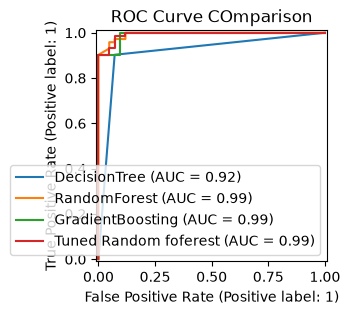

In [16]:
#comparing roc curves for all
plt.figure(figsize=(6,3))
for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, X_test, y_test, name= name, ax=plt.gca()
    )

RocCurveDisplay.from_estimator(
    best_rf, X_test, y_test, name="Tuned Random foferest", ax= plt.gca()
)
plt.title("ROC Curve COmparison")
plt.show()

# Observation
After comparing all the three models i figured that random forest and gradient boosting performed better than a single decision tree which recieved around 91% accuracy while random forest and gradient boosting got around 95.6%. Random Forest got the highest ROC-AUC approximately 0.9937 which even after tuning the model stayed almost the same but it slightly decreased from 0.9937 to 0.9931 so tuning didnt really improve the results in this. From the curves it can be seen that the decision tree curve is comparatively far from other models curves showing other models performed better.

In [17]:
# Trying bagging classifier

bagging_model= BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42
)
bagging_model.fit(X_train,y_train)
bagging_pred= bagging_model.predict(X_test)
bagging_prob= bagging_model.predict_proba(X_test)[:,1]

print( "accuracy: ", accuracy_score(y_test, bagging_pred))
print ("f1 score: ", f1_score(y_test, bagging_pred))
print ("ROC-AUC: ", roc_auc_score(y_test, bagging_prob))

accuracy:  0.9385964912280702
f1 score:  0.9517241379310345
ROC-AUC:  0.9927248677248678


# Observation 
I observed that bagging performed quite better than a single decision tree but slightly worse than Random forest and Gradient Boosting it helps the fact that combining multiple Trees is better than just one tree in terms of performance

In [25]:
# checking which features ar e important

importance= pd.Series(
    best_rf.feature_importances_ ,
    index= load_breast_cancer().feature_names
).sort_values(ascending=False)
importance.head()


worst area              0.143035
worst concave points    0.136068
worst radius            0.103568
mean concave points     0.099847
worst perimeter         0.071456
dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

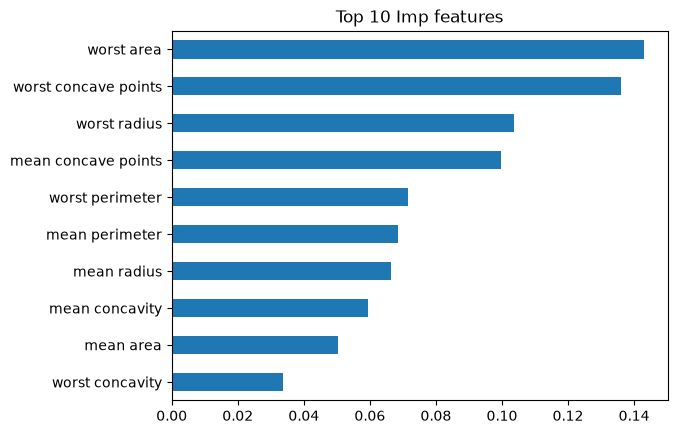

In [24]:
importance.head(10).plot(kind='barh')
plt.title('Top 10 Imp features')
plt.gca().invert_yaxis()
plt.show